In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from joblib import Parallel, delayed
import fspiderman as sp
import batman
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from kepler_utils import *
import batman_utils
from bias_analysis import *
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.0204                                 #planet radius [stellar radii / rs]
rs = 0.68                                   #stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]   
a = AU_to_RS(a_AU, rs)                      #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142e-6                                 #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
T_eff = 4570                                # stellar effective temperature [K]

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from K2-141 data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

Ag = 0.28                                   # Geometric albedo from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
A_B = 3/2*Ag                                # Assuming Lambertian reflectance. PROBABLY UNPHYSICAL!
A = A_B                                     # ASSUMPTION (!): Band-integrated albedo of rocky surface = bond albedo

In [3]:
# Define Exoplanet Object
K2_141b = PlanetParams(period=period, incl=incl, ecc=ecc, w=w, r1=rp, r2=1., R=a, T2_eff=T_eff, a_AU=a_AU)

In [4]:
# Wavelength ranges of various instruments in um. These are only effective ranges, used for approximate tophat filters.
effective_lambda_ranges = {
    "MIRI/F1280W": [11.6, 14.0], # MIRI imaging TSO, F1280W. Below CO₂ band, can check CO₂ atmosphere (combined with F1500W)
    "MIRI/F1500W": [13.5, 16.6], # MIRI imaging TSO, F1500W. Used on Trappist (15µm CO₂ band), Long wavelengths for cold nightside
    "MIRI/F1800W": [16.5, 19.5], # MIRI imaging TSO, F1800W. MIRI's thermal background climbs steeply past ~15 µm
    "MIRI/LRS": [5.0, 10.5], # Suggested by Sebastian, LRS runs to ~12 µm but red end trimmed (throughput drops)
    "Spitzer/IRAC2": [4.0, 5.0] # ~Spitzer IRAC channel 2 (4.5 um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)
}
for n, r in effective_lambda_ranges.items(): effective_lambda_ranges[n]=1e-6*np.array(r) # convert to meters

# Wavelength ranges of various instruments in um. These are the exact filter ranges to be used with the filter throughput data.
filter_lambda_ranges = {
    "MIRI/F1280W": [11.0654, 14.5816], # MIRI imaging TSO, F1280W. Below CO₂ band, can check CO₂ atmosphere (combined with F1500W)
    "MIRI/F1500W": [12.7875, 17.4925], # MIRI imaging TSO, F1500W. Used on Trappist (15µm CO₂ band), good for cold nightside
    "MIRI/F1800W": [15.5725, 20.8505], # MIRI imaging TSO, F1800W. MIRI's thermal background climbs steeply past ~15 µm
    "Spitzer/IRAC2": [3.6955, 5.1008], # ~Spitzer IRAC channel 2 (4.5 um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)
    "MIRI/LRS": [4.8900, 10.6100] # MIRI/LRS 5.0-10.5 um. Filter_paths for 5.0-12.0 um and 5.0-14.0 um are also available.
}
for n, r in filter_lambda_ranges.items(): filter_lambda_ranges[n]=1e-6*np.array(r) # convert to meters

FILTER_DIR = os.path.join(os.path.dirname(os.path.abspath('')), 'Filters', 'Spiderman')
filter_paths = {
    "MIRI/F1280W": os.path.join(FILTER_DIR, "JWST_MIRI.F1280W.spiderman.dat"),
    "MIRI/F1500W": os.path.join(FILTER_DIR, "JWST_MIRI.F1500W.spiderman.dat"),
    "MIRI/F1800W": os.path.join(FILTER_DIR, "JWST_MIRI.F1800W.spiderman.dat"),
    "Spitzer/IRAC2": os.path.join(FILTER_DIR, "Spitzer_IRAC.I2.spiderman.dat"),
    "MIRI/LRS": os.path.join(FILTER_DIR, "MIRI_LRS.5.0-10.5um.spiderman.dat")
}

In [5]:
# Filter to be used
lrs_path = filter_paths["MIRI/LRS"]
lrs_range = filter_lambda_ranges["MIRI/LRS"]

## Detectability and parameter bias analysis (MIRI/LRS 5.0-10.5 um)

For K2-141b, MIRI/LRS 5.0-10.5 um has a detection error of 323 ppm per minute.


In [6]:
minutes_binning = 15 # bin width [minutes]
sigma_1min      = 323. # detection error [ppm per minute], MIRI/LRS 5.0-10.5 um
n_orbits        = 10 # number of orbits observed (3 orbits has been done)

sigma_bin = sigma_1min / np.sqrt(minutes_binning * n_orbits) # [ppm]
print(f"period = {period*24*60:.1f} min -> {int(period*24*60/minutes_binning)} bins of {minutes_binning} min")
print(f"1-sigma per bin = {sigma_bin:.1f} ppm")

period = 403.6 min -> 26 bins of 15 min
1-sigma per bin = 26.4 ppm


### 1. Pure Detectability

In [7]:
# Full phase curve (reflected + thermal). The naive curve uses full_PhaseCurve(insolation_model="naive")
t = np.linspace(0., period, 1000)
t_k, pc_k, fp_k = full_PhaseCurve(K2_141b, lrs_range, t=t, u=u, filter_path=lrs_path, A=A, A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="hyperillum", u_B=u_B)
t_n, pc_n, fp_n = full_PhaseCurve(K2_141b, lrs_range, t=t, u=u, filter_path=lrs_path, A=A, A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="naive", u_B=u_B)

# Transit removed (phase modulation + occultation only) = reflected(no transit) + thermal(no transit), so the modulation is visible
_, refl_k, _     = reflected_PhaseCurve(K2_141b, t=t, u=u, include_transit=False, A=A, insolation_model="hyperillum", u_B=u_B)
_, therm_k, _, _ = thermal_PhaseCurve(K2_141b, lrs_range, t=t, u=u, filter_path=lrs_path, A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="hyperillum", include_transit=False, u_B=u_B)
lc_k = refl_k + therm_k
_, refl_n, _     = reflected_PhaseCurve(K2_141b, t=t, u=u, include_transit=False, A=A, insolation_model="naive", u_B=u_B)
_, therm_n, _, _ = thermal_PhaseCurve(K2_141b, lrs_range, t=t, u=u, filter_path=lrs_path, A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="naive", include_transit=False, u_B=u_B)
lc_n = refl_n + therm_n

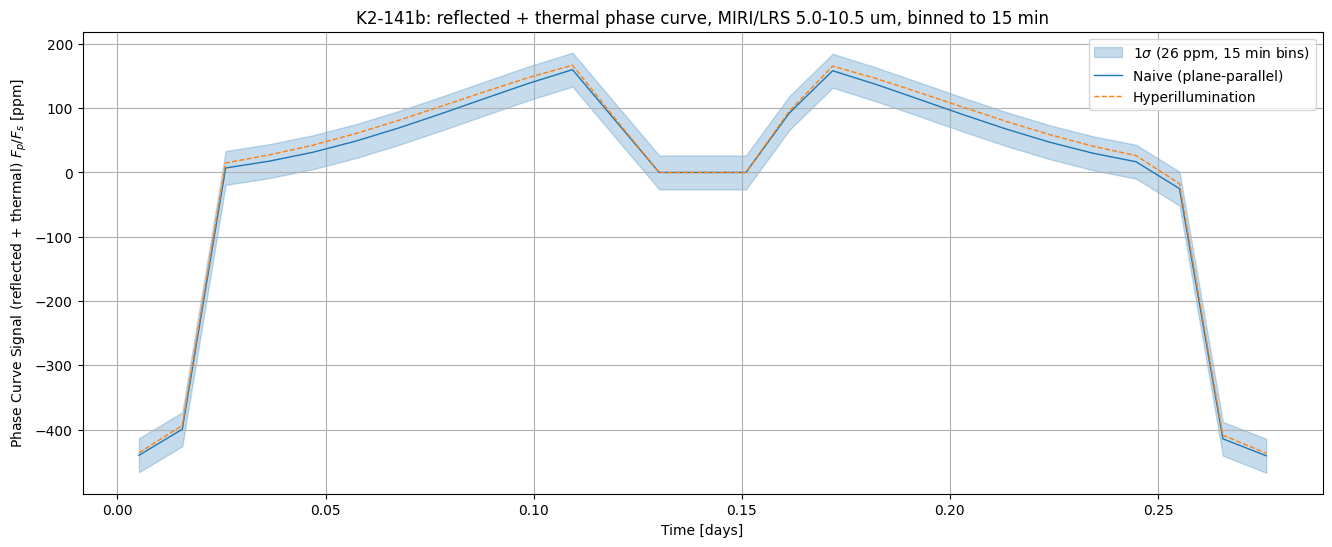

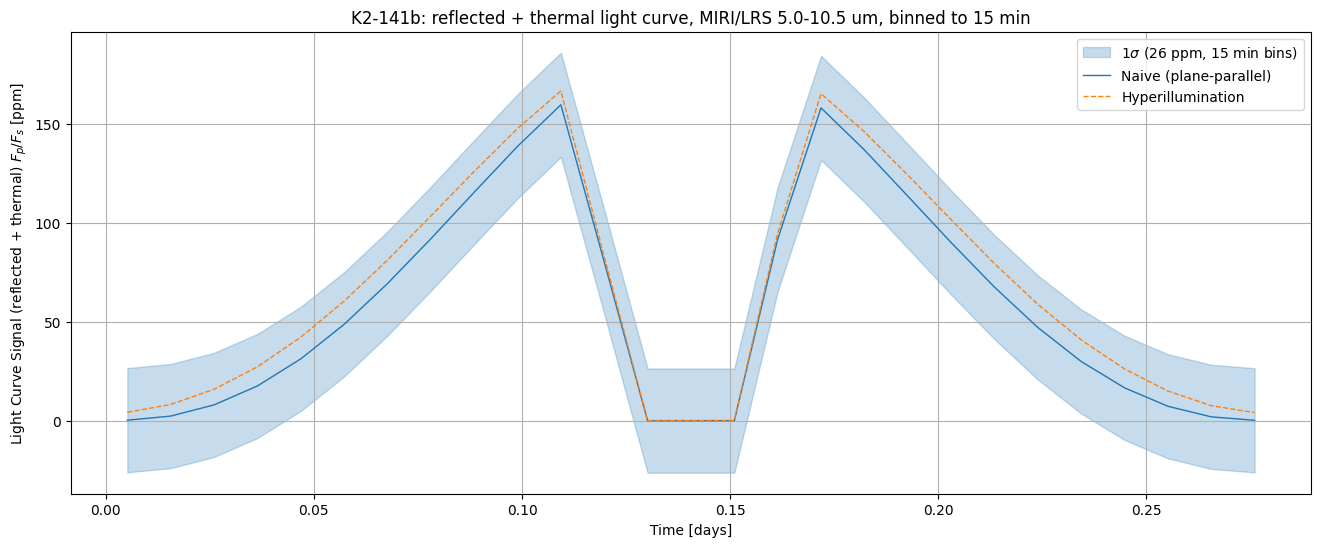

In [8]:
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_n, yb_n - sigma_bin, yb_n + sigma_bin, color="C0", alpha=0.25, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: reflected + thermal phase curve, MIRI/LRS 5.0-10.5 um, binned to {minutes_binning} min")
plt.legend(); plt.grid()
plt.show()

tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_n, yb_n - sigma_bin, yb_n + sigma_bin, color="C0", alpha=0.25, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: reflected + thermal light curve, MIRI/LRS 5.0-10.5 um, binned to {minutes_binning} min")
plt.legend(); plt.grid()
plt.show()

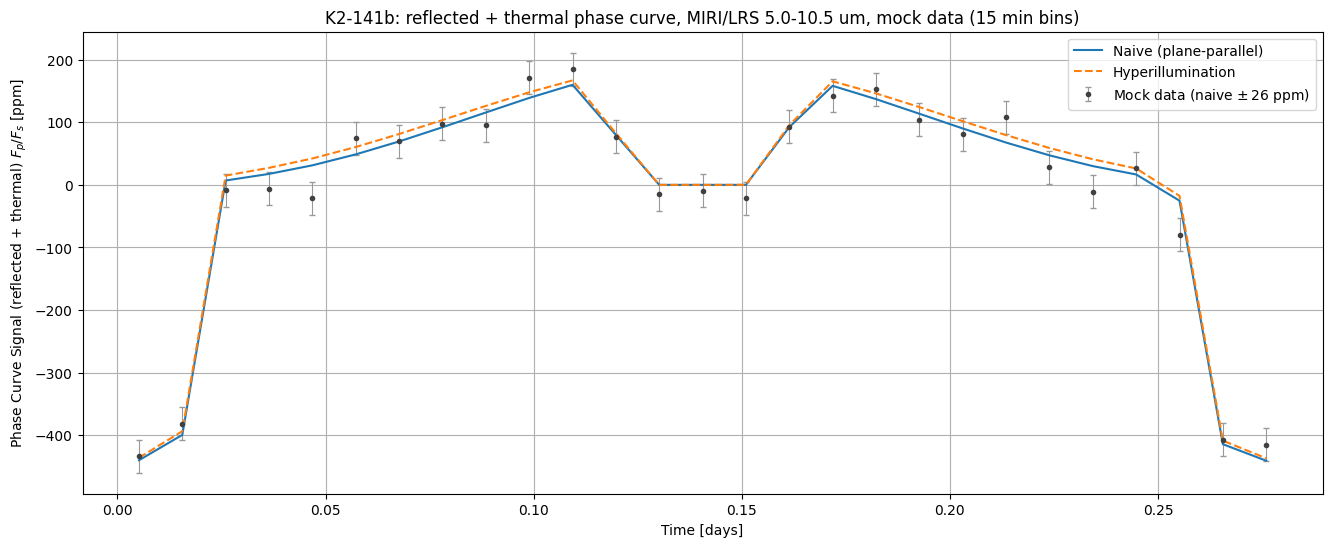

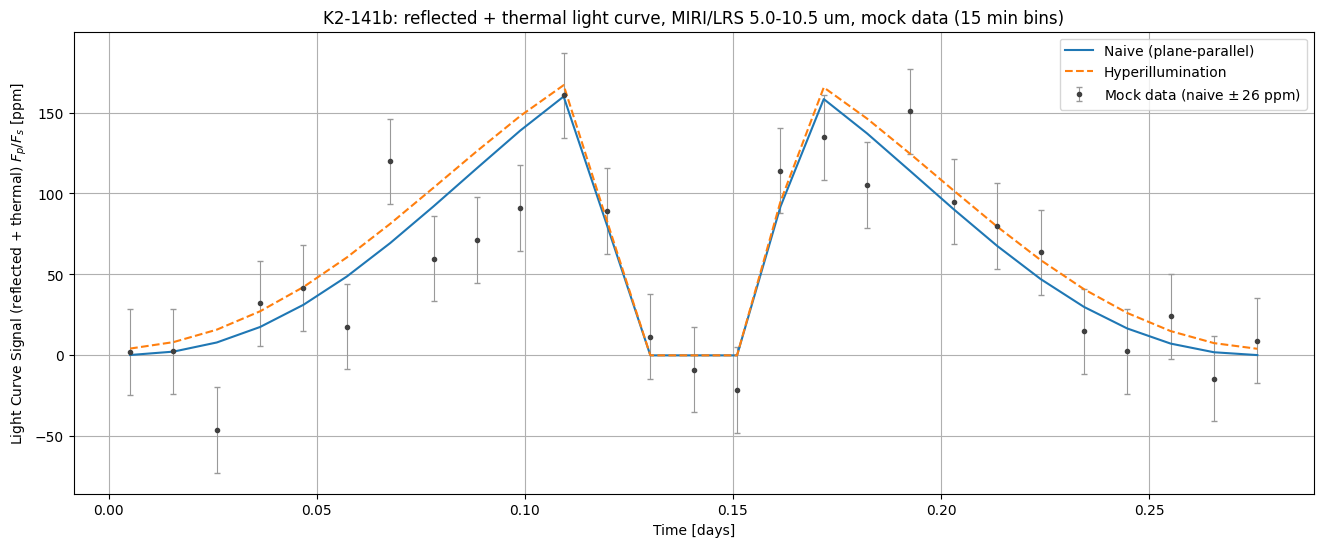

In [9]:
# Mock observation: at each binned time draw a data point ~ N(mean = naive model, std = sigma_bin),
rng = np.random.default_rng(43)   # fixed seed -> reproducible mock data

# --- Phase curve ---
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)   # naive model, binned [ppm]
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)   # hyperillumination model, binned [ppm]
y_data = yb_n + rng.normal(0., sigma_bin, size=yb_n.size)        # mock data ~ N(naive, sigma_bin)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_n, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (naive $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: reflected + thermal phase curve, MIRI/LRS 5.0-10.5 um, mock data ({minutes_binning} min bins)")
plt.legend(); plt.grid()
plt.show()

# --- Light curve ---
tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)
y_data = yb_n + rng.normal(0., sigma_bin, size=yb_n.size)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_n, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (naive $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: reflected + thermal light curve, MIRI/LRS 5.0-10.5 um, mock data ({minutes_binning} min bins)")
plt.legend(); plt.grid()
plt.show()

### 2. Bias in recovered Bond albedo when hyperillumination is neglected

In [10]:
l1, l2 = lrs_range
stellar_grid = sp.stellar_grid.gen_grid(l1, l2, logg=4.5, response=lrs_path)

A_B_true = A_B  # 3/2 * Ag(Zieba2022) = 0.42;  under A = A_B this single albedo sets BOTH the reflected amplitude and the Bond albedo (dayside temperature)

# context for the bias-analysis functions imported from bias_analysis.py
cfg = BiasConfig(planet=K2_141b, stellar_grid=stellar_grid, filter_path=lrs_path,
                 l1=l1, l2=l2, rs=rs, incl=incl, ecc=ecc, w=w, period=period,
                 a=a, T_eff=T_eff, rp=rp, A_B_true=A_B_true, sigma_bin=sigma_bin,
                 reflected=True, u_B=u_B)   # full = reflected + thermal; T_floor=200, bounds=(0.0, 0.6) by default

no stellar models provided, using blackbody approximation


In [11]:
# demo: fit the naive model to the hyperillumination truth and report the recovered-A_B bias
_, truth = model_lc(cfg, "hyperillum", A_B_true)

for free_offset in (False, True):
    A_fit, chi2 = fit_naive(cfg, truth, free_offset=free_offset)
    r = truth - model_lc(cfg, "naive", A_fit)[1]
    if free_offset: r = r - r.mean()
    print(f"free offset={str(free_offset):5s}  A_B: {A_B_true:.3f} -> {A_fit:.4f}  "
          f"bias={A_fit-A_B_true:+.4f} ({100*(A_fit-A_B_true)/A_B_true:+.1f}%)  "
          f"chi2={chi2:.4f}  resid_rms={np.sqrt(np.mean(r**2)):.2f} ppm  "
          f"significance={np.sqrt(chi2):.3f} sigma/observation")

free offset=False  A_B: 0.420 -> 0.0057  bias=-0.4143 (-98.6%)  chi2=32.6108  resid_rms=4.76 ppm  significance=5.711 sigma/observation
free offset=True   A_B: 0.420 -> 0.2849  bias=-0.1351 (-32.2%)  chi2=16.5702  resid_rms=3.39 ppm  significance=4.071 sigma/observation


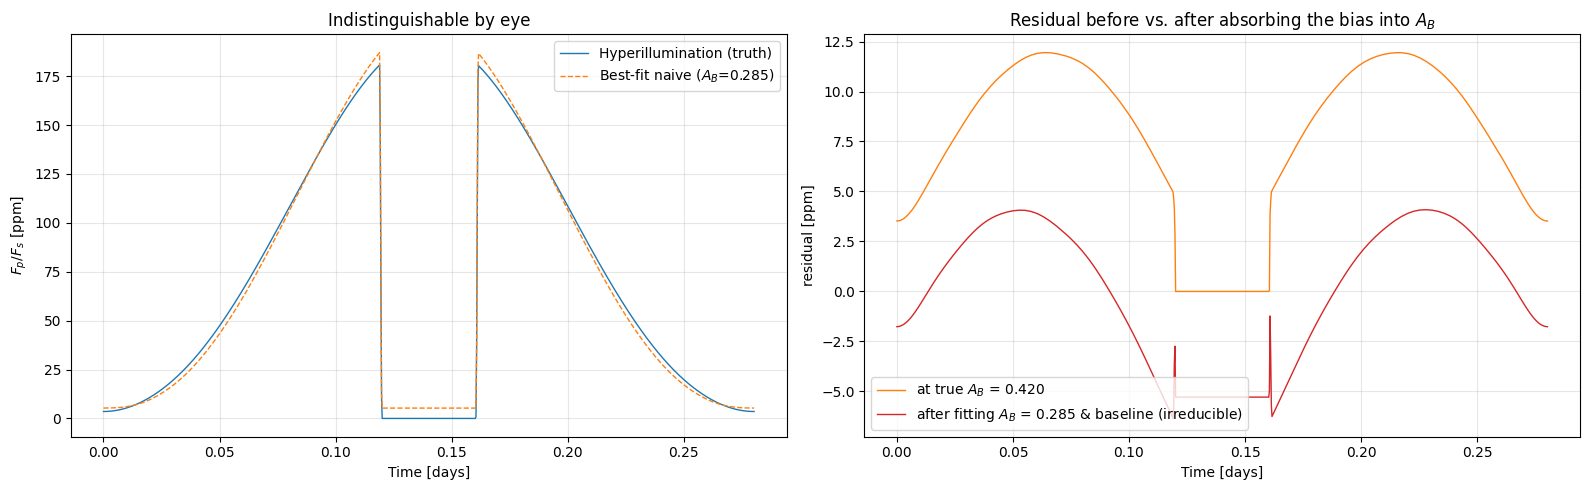

In [12]:
# before vs after absorbing the bias into A_B
t_, truth = model_lc(cfg, "hyperillum", A_B_true)
A_fit, _  = fit_naive(cfg, truth)
naive_0   = model_lc(cfg, "naive", A_B_true)[1]
naive_f   = model_lc(cfg, "naive", A_fit)[1]
naive_f   = naive_f + (truth - naive_f).mean()

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
# left: truth vs best-fit naive
ax[0].plot(t_, truth,   lw=1, label="Hyperillumination (truth)")
ax[0].plot(t_, naive_f, lw=1, ls="--", label=f"Best-fit naive ($A_B$={A_fit:.3f})")
ax[0].set_ylabel(r"$F_p/F_s$ [ppm]"); ax[0].set_xlabel("Time [days]")
ax[0].set_title("Indistinguishable by eye")
# right: both residuals combined on one axes
ax[1].plot(t_, truth - naive_0, lw=1, color="C1", label=rf"at true $A_B$ = {A_B_true:.3f}")
ax[1].plot(t_, truth - naive_f, lw=1, color="C3", label=rf"after fitting $A_B$ = {A_fit:.3f} & baseline (irreducible)")
ax[1].set_ylabel("residual [ppm]"); ax[1].set_xlabel("Time [days]")
ax[1].set_title(r"Residual before vs. after absorbing the bias into $A_B$")
for a_ in ax: a_.grid(alpha=.3); a_.legend()
fig.tight_layout()

### 3. In which regimes does hyperillumination matter? Bias map over (a/Rs, T_eff)

In [13]:
# The bias in recovered A_B is a pure model-degeneracy quantity, so this map is independent of the noise level sigma and of the target's brightness. The (a/Rs, T_eff) cells are independent -> run them in parallel (processes; joblib).
a_rs_grid  = np.linspace(1.5, 4.0, 20)
T_eff_grid = np.linspace(3000., 6000., 10)
kw = dict(n_t=1000, n_layers=40, n_lo=300, n_la=150)     # the 200 K T_floor in model_lc keeps the naive terminator spline stable at this resolution

flat = Parallel(n_jobs=-1, backend="loky")(
    delayed(bias_cell)(cfg, a_rs=ar, T_s=Ts, **kw) for Ts in T_eff_grid for ar in a_rs_grid)
bias_map = np.array(flat).reshape(len(T_eff_grid), len(a_rs_grid))
get_reusable_executor().shutdown(wait=True)  # free memory SPIDERMAN leaks in the workers before the next run


looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


/opt/anaconda3/envs/PhaseCurves/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file det

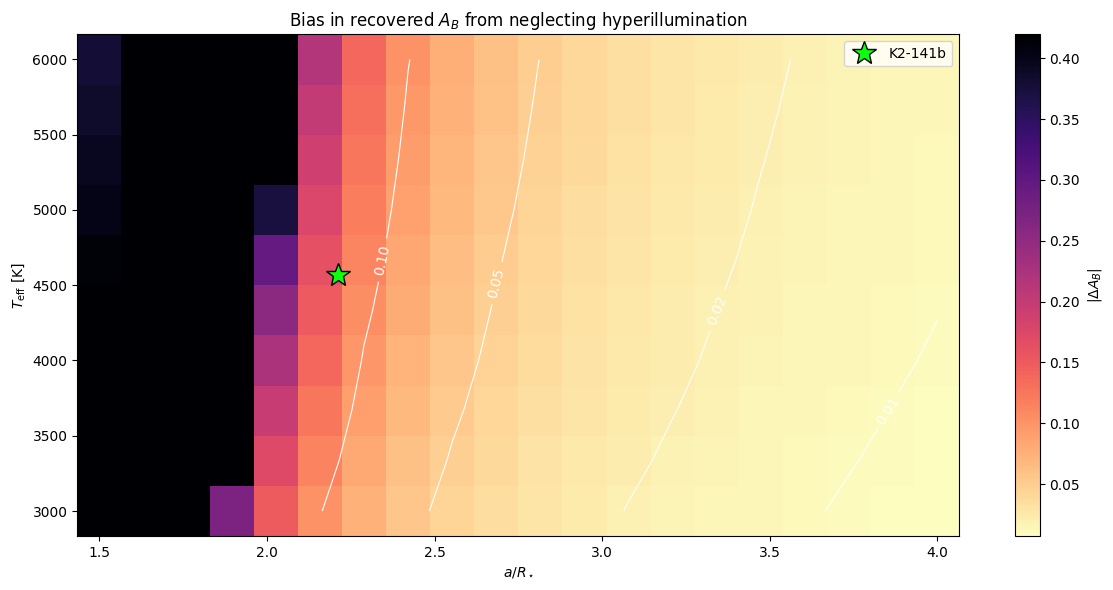

In [14]:
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.pcolormesh(a_rs_grid, T_eff_grid, np.abs(bias_map), cmap="magma_r", shading="auto")
cs = ax.contour(a_rs_grid, T_eff_grid, np.abs(bias_map), levels=[0.01, 0.02, 0.05, 0.10],
                colors="w", linewidths=.8)
ax.clabel(cs, fmt="%.2f")
ax.plot(a/1, T_eff, "*", color="#0cff0c", ms=18, mec="k", label="K2-141b")
ax.set_xlabel(r"$a/R_\star$"); ax.set_ylabel(r"$T_{\rm eff}$ [K]")
ax.set_title(r"Bias in recovered $A_B$ from neglecting hyperillumination")
fig.colorbar(im, ax=ax, label=r"$|\Delta A_B|$")
ax.legend(); fig.tight_layout()

### 4. In which regimes does hyperillumination matter? Bias map over (a/Rs, Rp/Rs)

In [15]:
a_rs_grid  = np.linspace(1.5, 4.0, 20)
rp_rs_grid = np.linspace(0.01, 0.1, 10)
kw = dict(n_t=1000, n_layers=40, n_lo=300, n_la=150)     # the 200 K T_floor in model_lc keeps the naive terminator spline stable at this resolution

flat = Parallel(n_jobs=-1, backend="loky")(
    delayed(bias_cell)(cfg, a_rs=ar, rp_=rpp, **kw) for rpp in rp_rs_grid for ar in a_rs_grid)
bias_map = np.array(flat).reshape(len(rp_rs_grid), len(a_rs_grid))
get_reusable_executor().shutdown(wait=True)  # free memory SPIDERMAN leaks in the workers before the next run


looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file det

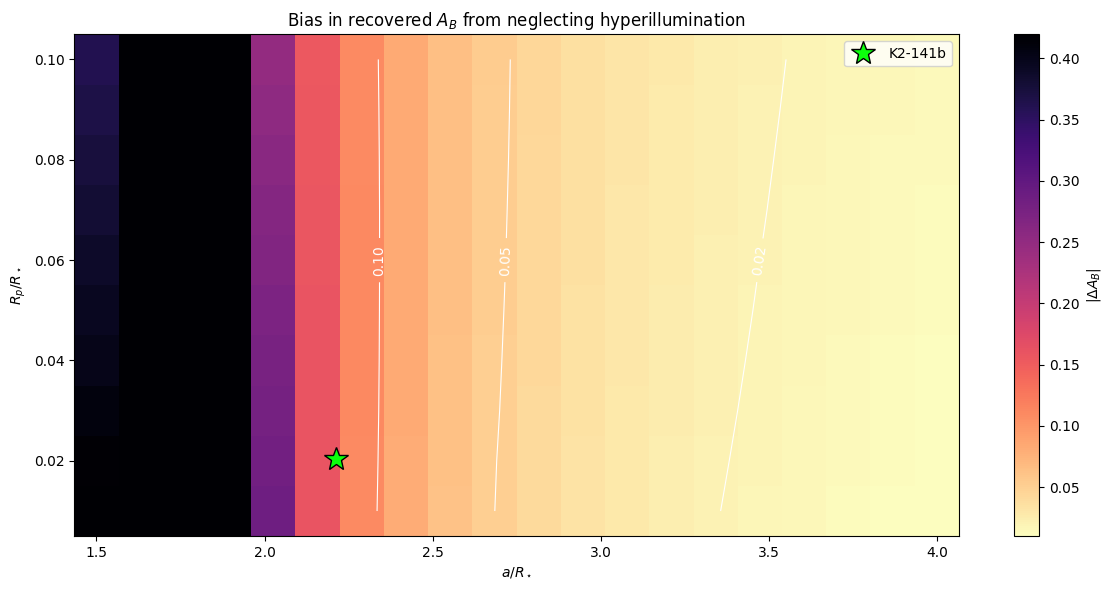

In [16]:
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.pcolormesh(a_rs_grid, rp_rs_grid, np.abs(bias_map), cmap="magma_r", shading="auto")
cs = ax.contour(a_rs_grid, rp_rs_grid, np.abs(bias_map), levels=[0.01, 0.02, 0.05, 0.10],
                colors="w", linewidths=.8)
ax.clabel(cs, fmt="%.2f")
ax.plot(a/1, rp, "*", color="#0cff0c", ms=18, mec="k", label="K2-141b")
ax.set_xlabel(r"$a/R_\star$"); ax.set_ylabel(r"$R_p/R_\star$")
ax.set_title(r"Bias in recovered $A_B$ from neglecting hyperillumination")
fig.colorbar(im, ax=ax, label=r"$|\Delta A_B|$")
ax.legend(); fig.tight_layout()